<a href="https://colab.research.google.com/github/trialdyk/PBL-Skin-Problem-Detector/blob/main/machine-learning/trialdyk/acne_severity_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Klasifikasi Tingkat Keparahan Jerawat (IGA)

Notebook ini melatih dan mengevaluasi model klasifikasi citra untuk tingkat keparahan jerawat pada dataset Roboflow Universe [taschenbier/acne-severity-classification](https://universe.roboflow.com/taschenbier/acne-severity-classification) (versi 3).

**Stack:** TensorFlow/Keras, transfer learning EfficientNet, Google Colab (GPU).

## Ringkasan pipeline

| # | Tahap | Tujuan | Metode |
|---|---|---|---|
| 1 | Pengunduhan data | Mengambil dataset dalam struktur folder per kelas | Roboflow API / zip manual |
| 2 | Eksplorasi data | Melihat distribusi kelas dan perbedaan gaya gambar antar kelas | Statistik per kelas, proporsi piksel hitam |
| 3 | Preprocessing | Menyeragamkan bingkai gambar | Crop area konten (thresholding + bounding box) |
| 4 | Pemeriksaan kebocoran | Memastikan data evaluasi tidak memuat duplikat data latih | Perceptual hash (dHash) + jarak Hamming |
| 5 | Input pipeline | Menyiapkan batch dan menangani ketidakseimbangan kelas | `tf.data`, oversampling, soft label ordinal |
| 6 | Augmentasi | Meningkatkan variasi data, mengurangi ketergantungan pada latar | Augmentasi geometri/warna, *background randomization* |
| 7 | Model | Ekstraksi fitur visual | EfficientNet pretrained ImageNet + classification head |
| 8 | Training | Melatih head, lalu menyetel sebagian backbone | Feature extraction → fine-tuning, focal loss, Adam |
| 9 | Evaluasi | Mengukur kualitas prediksi | Accuracy, macro-F1, confusion matrix, bootstrap CI, metrik ordinal dan kelompok |
| 10 | Uji ketahanan | Mengecek apakah prediksi bergantung pada latar | Penggantian piksel latar saat inferensi |
| 11 | Interpretasi | Melihat area gambar yang memengaruhi prediksi | Analisis kesalahan, Grad-CAM |
| 12 | Ekspor | Menyiapkan model untuk aplikasi | TFLite float16 |
| 13 | Cross-validation (opsional) | Estimasi performa yang lebih stabil | Stratified group k-fold |

## 1. Setup

**Langkah:** memasang dependensi dan mengimpor pustaka, mengatur seed, memeriksa GPU.
**Metode:** seed tetap untuk reproduktibilitas; OpenCV untuk pemrosesan gambar; scikit-learn untuk metrik dan pembagian data.

In [5]:
!pip install -q roboflow seaborn

In [6]:
import os, random, pathlib, json, shutil, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__, "| OpenCV:", cv2.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU:", gpus if gpus else "tidak tersedia (training akan sangat lambat)")

TensorFlow: 2.21.0 | OpenCV: 4.14.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Konfigurasi

Seluruh parameter eksperimen dikumpulkan di satu sel. API key Roboflow diisi pada `ROBOFLOW_API_KEY`, atau dibaca dari Colab Secret bernama `ROBOFLOW_API_KEY`.

Parameter utama:
- `CLASS_MERGE`: menggabungkan folder kelas. Default menggabungkan `IGA3_Level3` ke `IGA3` sehingga klasifikasi tetap 5 kelas (IGA0-IGA4).
- `ORDINAL_ORDER`: urutan kelas dari ringan ke berat; dipakai untuk soft label dan metrik ordinal. Entri yang tidak ada di data diabaikan.
- `COARSE_GROUPS`: pengelompokan kelas menjadi tingkat yang lebih kasar untuk evaluasi tambahan (nonaktif secara default; klasifikasi utama tetap 5 kelas).
- `USE_CONTENT_CROP`, `BG_RANDOMIZE`: preprocessing dan augmentasi latar.
- `RUN_CV`: mengaktifkan cross-validation di bagian akhir.

In [7]:
# ---------------- Dataset ----------------
ROBOFLOW_API_KEY = "qISnqZnszyWyuLZCRjTE"
try:
    from google.colab import userdata
    ROBOFLOW_API_KEY = userdata.get("ROBOFLOW_API_KEY")
except Exception:
    pass

WORKSPACE = "taschenbier"
PROJECT   = "acne-severity-classification"
VERSION   = 3
EXPORT_FORMAT = "folder"
ZIP_PATH  = None                       # contoh: "/content/acne.zip" (melewati API)

CLASS_MERGE = {"IGA3_Level3": "IGA3"}   # hasil akhir 5 kelas: IGA0-IGA4 (tidak berpengaruh bila folder tidak ada)
ORDINAL_ORDER = ["IGA0", "IGA1", "IGA2", "IGA3", "IGA4"]
ORDINAL_SOFT_LABELS = True
ORDINAL_TAU = 0.5
COARSE_GROUPS = None                   # opsional, contoh: {"IGA0": "bersih", "IGA1": "bersih", "IGA2": "sedang", "IGA3": "berat", "IGA4": "berat"}

# ---------------- Preprocessing & augmentasi latar ----------------
USE_CONTENT_CROP = True
CROP_THRESH   = 15                     # piksel dianggap "kosong" bila nilai maksimum RGB <= nilai ini
CROP_MIN_FRAC = 0.02                   # baris/kolom dianggap berisi konten bila >2% pikselnya non-kosong
CROP_MARGIN   = 0.02
BG_RANDOMIZE  = True                   # ganti piksel hitam latar dengan warna/noise acak saat training
BG_PROB       = 0.5
BG_THRESH     = 12
DROP_NEAR_DUPLICATES = True            # buang gambar val/test yang nyaris identik dengan gambar train
HASH_DIST     = 3                      # ambang jarak Hamming (dari 64 bit)

# ---------------- Model ----------------
BACKBONE = "EfficientNetB2"
NATIVE_RES = {"EfficientNetB0": 224, "EfficientNetB1": 240, "EfficientNetB2": 260,
              "EfficientNetB3": 300, "EfficientNetB4": 380}
IMG_SIZE = NATIVE_RES[BACKBONE]
BATCH_SIZE = 16
DROPOUT = 0.4

# ---------------- Training ----------------
EPOCHS_STAGE1 = 5
EPOCHS_STAGE2 = 35
LR_STAGE1 = 1e-3
LR_STAGE2 = 3e-5
UNFREEZE_LAST_N = 100
SEEDS = [42]                           # satu model per seed; lebih dari satu seed = ensemble
IMBALANCE_STRATEGY = "oversample"      # "oversample" | "class_weight" | "none"
LOSS = "focal"                         # "focal" | "crossentropy"
FOCAL_GAMMA = 2.0
LABEL_SMOOTHING = 0.1

# ---------------- Inferensi ----------------
USE_ENSEMBLE = True
USE_TTA = False

# ---------------- Cross-validation (opsional) ----------------
RUN_CV = False
N_FOLDS = 5
FOLDS_TO_RUN = [0]

os.makedirs("outputs", exist_ok=True)

## 3. Pengunduhan dataset

**Langkah:** mengunduh dataset dalam format `folder` (`train|valid|test / <kelas> / *.jpg`).
**Metode:** Roboflow Python SDK, atau ekstraksi zip yang diunduh manual dari halaman dataset (*Download Dataset → Folder Structure*).

In [8]:
if ZIP_PATH:
    DATA_DIR = pathlib.Path("dataset_zip")
    shutil.rmtree(DATA_DIR, ignore_errors=True)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)
    subs = [p for p in DATA_DIR.iterdir() if p.is_dir()]
    if len(subs) == 1 and not any((DATA_DIR / n).is_dir() for n in ("train", "valid", "val", "test")):
        DATA_DIR = subs[0]
else:
    if not ROBOFLOW_API_KEY or ROBOFLOW_API_KEY == "ISI_API_KEY_ANDA":
        raise ValueError("API key belum diisi (ROBOFLOW_API_KEY) dan ZIP_PATH kosong.")
    from roboflow import Roboflow
    rf = Roboflow(api_key=ROBOFLOW_API_KEY)
    dataset = rf.workspace(WORKSPACE).project(PROJECT).version(VERSION).download(EXPORT_FORMAT)
    DATA_DIR = pathlib.Path(dataset.location)

print("Lokasi dataset:", DATA_DIR, "| isi:", sorted(p.name for p in DATA_DIR.iterdir()))

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Acne-Severity-Classification-3 in folder:: 100%|██████████| 6471/6471 [00:02<00:00, 3107.14it/s]


Lokasi dataset: /content/Acne-Severity-Classification-3 | isi: ['README.dataset.txt', 'README.roboflow.txt', 'test', 'train', 'valid']


## 4. Eksplorasi data

**Langkah:** menghitung jumlah gambar per kelas dan split, mengukur proporsi piksel hitam per kelas, dan menampilkan contoh gambar.
**Metode:** statistik deskriptif. Proporsi piksel hitam (nilai maksimum RGB < 15) menjadi indikator perbedaan gaya gambar (latar hitam/letterbox) antar kelas. Perbedaan yang besar antar kelas menandakan risiko model mempelajari gaya gambar, bukan lesi.

Kelas: ['IGA0', 'IGA1', 'IGA2', 'IGA3', 'IGA4']


split,test,train,valid
class,,,
IGA0,30,1113,78
IGA1,20,1257,48
IGA2,58,2730,136
IGA3,16,501,34
IGA4,11,390,29


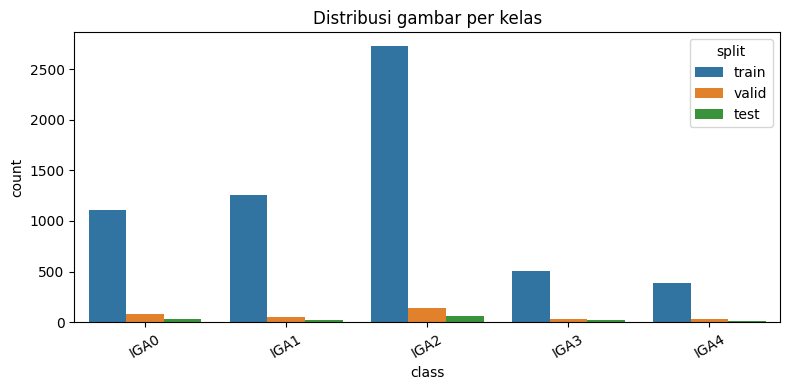

In [9]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def locate(data_dir):
    def find(*names):
        for n in names:
            p = data_dir / n
            if p.is_dir():
                return p
        return None
    return find("train"), find("valid", "val", "validation"), find("test")

train_dir, val_dir, test_dir = locate(DATA_DIR)
assert train_dir is not None, "Folder 'train' tidak ditemukan."
class_names = sorted({CLASS_MERGE.get(p.name, p.name) for p in train_dir.iterdir() if p.is_dir()})
NUM_CLASSES = len(class_names)
print("Kelas:", class_names)

def list_split(d):
    paths, labels = [], []
    if d is None:
        return paths, labels
    for cd in sorted(p for p in d.iterdir() if p.is_dir()):
        target = CLASS_MERGE.get(cd.name, cd.name)
        if target not in class_names:
            print(f"[!] Folder '{cd.name}' di {d.name} tidak ada di train, dilewati.")
            continue
        i = class_names.index(target)
        for f in sorted(cd.iterdir()):
            if f.suffix.lower() in IMG_EXT:
                paths.append(str(f)); labels.append(i)
    return paths, labels

rows = []
for name, d in [("train", train_dir), ("valid", val_dir), ("test", test_dir)]:
    _, lab = list_split(d)
    lab = np.array(lab)
    for i, c in enumerate(class_names):
        rows.append({"split": name, "class": c, "count": int((lab == i).sum()) if len(lab) else 0})
df_count = pd.DataFrame(rows)
display(df_count.pivot(index="class", columns="split", values="count"))
plt.figure(figsize=(8, 4))
sns.barplot(data=df_count[df_count["count"] > 0], x="class", y="count", hue="split")
plt.title("Distribusi gambar per kelas"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

,class,n_sampel,rata2_piksel_hitam,persen_gambar_>10%_hitam
0,IGA0,200,0.373,0.720
1,IGA1,200,0.202,0.715
2,IGA2,200,0.285,0.700
3,IGA3,200,0.185,0.625
4,IGA4,200,0.215,0.650


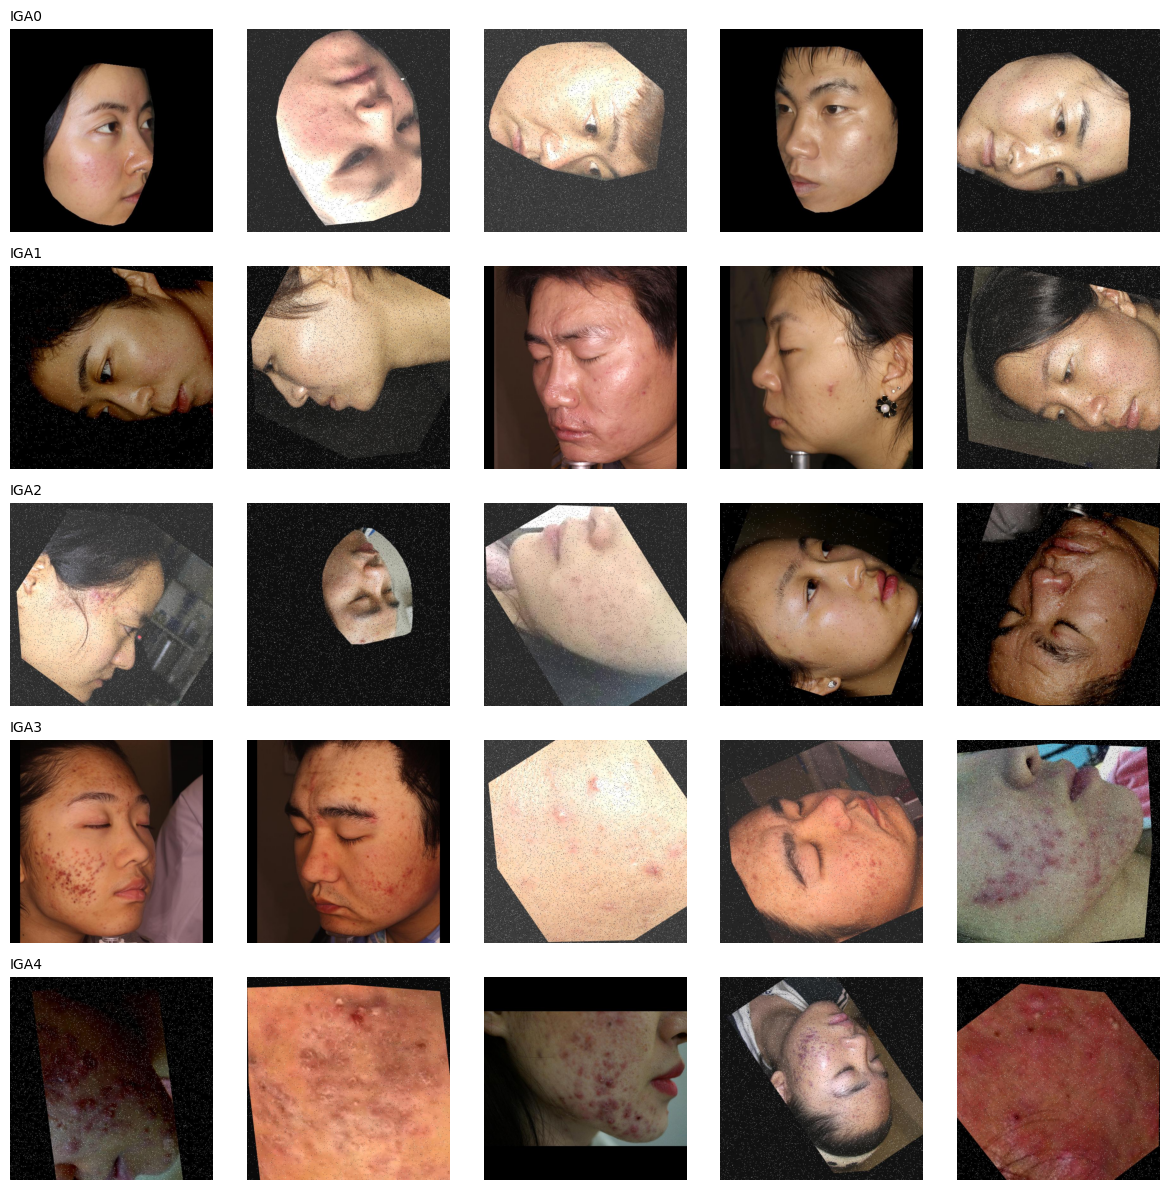

In [10]:
def black_frac(path):
    a = np.asarray(keras.utils.load_img(path, target_size=(128, 128)))
    return float((a.max(axis=2) < 15).mean())

p_tr, l_tr = list_split(train_dir)
l_tr = np.array(l_tr)
stat = []
for i, c in enumerate(class_names):
    ps = [p for p, l in zip(p_tr, l_tr) if l == i]
    ps = random.sample(ps, min(200, len(ps)))
    fr = np.array([black_frac(p) for p in ps])
    stat.append({"class": c, "n_sampel": len(ps), "rata2_piksel_hitam": fr.mean(),
                 "persen_gambar_>10%_hitam": (fr > 0.10).mean()})
display(pd.DataFrame(stat).round(3))

fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(12, 2.4 * NUM_CLASSES), squeeze=False)
for i, c in enumerate(class_names):
    ps = [p for p, l in zip(p_tr, l_tr) if l == i]
    for j, p in enumerate(random.sample(ps, min(5, len(ps)))):
        axes[i][j].imshow(keras.utils.load_img(p)); axes[i][j].axis("off")
        if j == 0:
            axes[i][j].set_title(c, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## 5. Preprocessing: crop area konten

**Langkah:** memotong tepi kosong (letterbox hitam atau latar hitam di sekeliling objek) sehingga area kulit mengisi bingkai.
**Metode:** thresholding intensitas (piksel dengan nilai maksimum RGB di atas `CROP_THRESH` dianggap konten), proyeksi baris/kolom untuk menentukan bounding box konten, penambahan margin kecil. Gambar yang tidak memiliki tepi kosong tidak berubah. Hasil disimpan ke folder baru dengan struktur yang sama.

Setelah crop, gambar di-resize langsung ke `IMG_SIZE × IMG_SIZE` pada tahap input pipeline.

In [11]:
def content_bbox(img):
    mask = img.max(axis=2) > CROP_THRESH
    rows = mask.mean(axis=1) > CROP_MIN_FRAC
    cols = mask.mean(axis=0) > CROP_MIN_FRAC
    if not rows.any() or not cols.any():
        return None
    y0, y1 = np.where(rows)[0][[0, -1]]
    x0, x1 = np.where(cols)[0][[0, -1]]
    h, w = img.shape[:2]
    my, mx = int(CROP_MARGIN * h), int(CROP_MARGIN * w)
    return max(0, x0 - mx), max(0, y0 - my), min(w, x1 + 1 + mx), min(h, y1 + 1 + my)

if USE_CONTENT_CROP:
    PREP_DIR = pathlib.Path("dataset_prep")
    shutil.rmtree(PREP_DIR, ignore_errors=True)
    n_total = n_cropped = 0
    for split_dir in [d for d in (train_dir, val_dir, test_dir) if d is not None]:
        for p in split_dir.rglob("*"):
            if p.suffix.lower() not in IMG_EXT:
                continue
            img = cv2.imread(str(p))
            if img is None:
                continue
            n_total += 1
            bb = content_bbox(img)
            if bb is not None:
                x0, y0, x1, y1 = bb
                area_ratio = ((x1 - x0) * (y1 - y0)) / (img.shape[0] * img.shape[1])
                if 0.2 < area_ratio < 0.90:       # abaikan crop degenerate; hanya crop bila ada tepi kosong berarti
                    img = img[y0:y1, x0:x1]
                    n_cropped += 1
            out = PREP_DIR / p.relative_to(DATA_DIR)
            out.parent.mkdir(parents=True, exist_ok=True)
            cv2.imwrite(str(out), img)
    print(f"Gambar dipotong: {n_cropped}/{n_total} ({n_cropped / max(1, n_total):.0%})")
    ORIG_DIR, DATA_DIR = DATA_DIR, PREP_DIR
    train_dir, val_dir, test_dir = locate(DATA_DIR)

Gambar dipotong: 1250/6451 (19%)


## 6. Pembagian data dan pemeriksaan kebocoran

**Langkah:** menyusun daftar file per split, lalu memeriksa apakah gambar validasi/test memiliki duplikat atau kemiripan ekstrem dengan gambar train.
**Metode:** *difference hash* (dHash) 64-bit per gambar; kemiripan diukur dengan jarak Hamming. Gambar val/test dengan jarak minimum ke train ≤ `HASH_DIST` ditandai dan (opsional) dibuang. Pemeriksaan ini hanya menangkap duplikat yang identik atau hampir identik; versi hasil augmentasi geometri berat tidak terdeteksi.

Identitas grup gambar diturunkan dari nama file (bagian sebelum `.rf.`), sehingga salinan hasil augmentasi Roboflow dari gambar yang sama berada dalam satu grup.

In [12]:
def group_of(path):
    name = os.path.basename(path)
    return name.split(".rf.")[0] if ".rf." in name else os.path.splitext(name)[0]

tr_paths, tr_labels = list_split(train_dir)
va_paths, va_labels = list_split(val_dir)
te_paths, te_labels = list_split(test_dir)
POOL_PATHS  = np.array(tr_paths + va_paths + te_paths)
POOL_LABELS = np.array(tr_labels + va_labels + te_labels)

tr_paths, tr_labels = np.array(tr_paths), np.array(tr_labels)
if not va_paths:
    g = np.array([group_of(p) for p in tr_paths])
    tr_i, va_i = next(StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED).split(tr_paths, tr_labels, g))
    va_paths, va_labels = list(tr_paths[va_i]), list(tr_labels[va_i])
    tr_paths, tr_labels = tr_paths[tr_i], tr_labels[tr_i]
    print("[!] Split valid tidak ada: 1/6 data train dipisah sebagai validasi (stratified, per grup).")
va_paths, va_labels = np.array(va_paths), np.array(va_labels)
HAS_TEST = len(te_paths) > 0
if not HAS_TEST:
    print("[!] Split test tidak ada: evaluasi memakai data validasi.")
    te_paths, te_labels = list(va_paths), list(va_labels)
te_paths, te_labels = np.array(te_paths), np.array(te_labels)

def dhash(path, size=8):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return 0
    img = cv2.resize(img, (size + 1, size), interpolation=cv2.INTER_AREA)
    bits = (img[:, 1:] > img[:, :-1]).flatten()
    return int(np.packbits(bits).view(">u8")[0])

def hashes(paths):
    return np.array([dhash(p) for p in paths], dtype=np.uint64)

def min_hamming(a, b, chunk=64):
    out = np.empty(len(a), dtype=int)
    for s in range(0, len(a), chunk):
        x = np.bitwise_xor(a[s:s + chunk, None], b[None, :])
        bits = np.unpackbits(x.view(np.uint8).reshape(x.shape[0], x.shape[1], 8), axis=-1)
        out[s:s + chunk] = bits.sum(-1).min(axis=1)
    return out

h_tr = hashes(tr_paths)
for name in ("val", "test"):
    P = va_paths if name == "val" else te_paths
    if name == "test" and not HAS_TEST:
        continue
    d = min_hamming(hashes(P), h_tr)
    flagged = d <= HASH_DIST
    print(f"{name}: {flagged.sum()}/{len(P)} gambar nyaris identik dengan gambar train (jarak <= {HASH_DIST})")
    if DROP_NEAR_DUPLICATES and flagged.any():
        keep = ~flagged
        if name == "val":
            va_paths, va_labels = va_paths[keep], va_labels[keep]
        else:
            te_paths, te_labels = te_paths[keep], te_labels[keep]
if not HAS_TEST:
    te_paths, te_labels = va_paths, va_labels
print(f"Ukuran akhir -> train={len(tr_paths)}  valid={len(va_paths)}  eval={len(te_paths)}")

val: 144/325 gambar nyaris identik dengan gambar train (jarak <= 3)
test: 66/135 gambar nyaris identik dengan gambar train (jarak <= 3)
Ukuran akhir -> train=5991  valid=181  eval=69


## 7. Input pipeline

**Langkah:** membangun dataset `tf.data` dari daftar file: decode, resize ke `IMG_SIZE`, batching, prefetch.

**Metode:**
- **Oversampling:** setiap epoch kelas minoritas diambil ulang (dengan pengembalian) hingga sama banyak dengan kelas terbesar. Alternatif: *class weighting* dengan bobot $w_c = N / (K \cdot n_c)$. Hanya satu dari keduanya yang dipakai (`IMBALANCE_STRATEGY`).
- **Soft label ordinal:** karena tingkat keparahan berurutan, label one-hot diganti distribusi yang menyisakan massa untuk kelas bersebelahan:
  $$ M_{ij} = \frac{\exp(-|r_i - r_j|/\tau)}{\sum_k \exp(-|r_i - r_k|/\tau)} $$
  dengan $r$ peringkat kelas. Aktif bila `ORDINAL_ORDER` terisi. Evaluasi tetap memakai label keras.
- **Background randomization (khusus training):** piksel latar hitam (nilai maksimum RGB < `BG_THRESH`) diganti warna solid atau noise acak dengan peluang `BG_PROB`. Tujuannya mengurangi ketergantungan model pada latar hitam dan sudut kosong hasil rotasi.

In [13]:
AUTOTUNE = tf.data.AUTOTUNE

SOFT_M = None
if ORDINAL_ORDER is not None and ORDINAL_SOFT_LABELS:
    ORD = [c for c in ORDINAL_ORDER if c in class_names]
    missing = [c for c in class_names if c not in ORD]
    assert not missing, f"ORDINAL_ORDER belum memuat kelas: {missing}"
    rank = np.array([ORD.index(c) for c in class_names])
    SOFT_M = np.exp(-np.abs(rank[:, None] - rank[None, :]) / ORDINAL_TAU)
    SOFT_M = (SOFT_M / SOFT_M.sum(1, keepdims=True)).astype("float32")

def decode(path):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img.set_shape((IMG_SIZE, IMG_SIZE, 3))
    return tf.cast(img, tf.float32)

def randomize_background(img):
    mask = tf.reduce_max(img, axis=-1, keepdims=True) < BG_THRESH
    solid = tf.ones_like(img) * tf.random.uniform([1, 1, 3], 0.0, 255.0)
    noise = tf.random.uniform(tf.shape(img), 0.0, 255.0)
    bg = tf.where(tf.random.uniform([]) < 0.5, solid, noise)
    apply = tf.random.uniform([]) < BG_PROB
    return tf.where(tf.logical_and(mask, apply), bg, img)

def fill_background(img, value):
    mask = tf.reduce_max(img, axis=-1, keepdims=True) < BG_THRESH
    return tf.where(mask, tf.fill(tf.shape(img), tf.cast(value, tf.float32)), img)

def balanced_indices(labels, rng):
    idx_by_c = [np.where(labels == c)[0] for c in range(NUM_CLASSES)]
    target = max(len(i) for i in idx_by_c)
    out = []
    for idx in idx_by_c:
        if len(idx) == 0:
            continue
        extra = rng.choice(idx, target - len(idx), replace=True) if len(idx) < target else []
        out.append(np.concatenate([idx, extra]).astype(int))
    return np.concatenate(out)

def make_ds(paths, labels, training=False, oversample=False, soft=False, seed=SEED, bg_fill=None):
    paths, labels = np.array(paths), np.array(labels)
    idx = balanced_indices(labels, np.random.default_rng(seed)) if (training and oversample) else np.arange(len(labels))
    y = np.eye(NUM_CLASSES, dtype="float32")[labels[idx]]
    if soft and SOFT_M is not None:
        y = y @ SOFT_M
    ds = tf.data.Dataset.from_tensor_slices((paths[idx], y))
    if training:
        ds = ds.shuffle(len(idx), seed=seed, reshuffle_each_iteration=True)

    def prep(p, t):
        img = decode(p)
        if training and BG_RANDOMIZE:
            img = randomize_background(img)
        if bg_fill is not None:
            img = fill_background(img, bg_fill)
        return img, t

    return ds.map(prep, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

counts = np.bincount(tr_labels, minlength=NUM_CLASSES)
print("Jumlah train per kelas:", dict(zip(class_names, counts)))

Jumlah train per kelas: {'IGA0': np.int64(1113), 'IGA1': np.int64(1257), 'IGA2': np.int64(2730), 'IGA3': np.int64(501), 'IGA4': np.int64(390)}


## 8. Loss

**Langkah:** mendefinisikan fungsi loss.
**Metode:** **focal loss** menurunkan bobot sampel yang sudah mudah diklasifikasi sehingga gradien didominasi sampel sulit:
$$ FL(p_t) = -(1 - p_t)^{\gamma} \log(p_t) $$
Dengan $\gamma = 0$ setara cross-entropy. *Label smoothing* diterapkan bila soft label ordinal tidak aktif.

In [14]:
class CategoricalFocalLoss(keras.losses.Loss):
    def __init__(self, gamma=2.0, label_smoothing=0.0, name="categorical_focal_loss", **kwargs):
        super().__init__(name=name, **kwargs)
        self.gamma = gamma
        self.label_smoothing = label_smoothing

    def call(self, y_true, y_pred):
        y_true = tf.cast(y_true, y_pred.dtype)
        k = tf.cast(tf.shape(y_pred)[-1], y_pred.dtype)
        y_true = y_true * (1.0 - self.label_smoothing) + self.label_smoothing / k
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        ce = -y_true * tf.math.log(y_pred)
        return tf.reduce_sum(tf.pow(1.0 - y_pred, self.gamma) * ce, axis=-1)

    def get_config(self):
        cfg = super().get_config()
        cfg.update(gamma=self.gamma, label_smoothing=self.label_smoothing)
        return cfg

def make_loss():
    ls = 0.0 if SOFT_M is not None else LABEL_SMOOTHING
    if LOSS == "focal":
        return CategoricalFocalLoss(gamma=FOCAL_GAMMA, label_smoothing=ls)
    return keras.losses.CategoricalCrossentropy(label_smoothing=ls)

## 9. Model dan prosedur training

**Langkah:** membangun model dan melatihnya dalam dua tahap.

**Metode:**
- **Transfer learning:** backbone EfficientNet dengan bobot ImageNet (`include_top=False`) sebagai ekstraktor fitur. EfficientNet memakai compound scaling, blok MBConv, dan Squeeze-and-Excitation.
- **Head klasifikasi:** GlobalAveragePooling → BatchNormalization → Dropout → Dense softmax.
- **Augmentasi di dalam model:** flip horizontal, rotasi, zoom, kontras, brightness; hanya aktif saat training.
- **Tahap 1 (feature extraction):** backbone dibekukan, head dilatih dengan LR tinggi.
- **Tahap 2 (fine-tuning):** `UNFREEZE_LAST_N` layer terakhir backbone dibuka dengan LR kecil; layer BatchNormalization tetap beku.
- **Optimizer** Adam; **callback** ModelCheckpoint, EarlyStopping (mengembalikan bobot terbaik), dan ReduceLROnPlateau.

In [15]:
def build_model(seed, tag="main"):
    keras.utils.set_random_seed(seed)
    aug = keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.10),
        layers.RandomContrast(0.15),
        layers.RandomBrightness(0.15),
    ], name="augmentation")
    base = getattr(keras.applications, BACKBONE)(
        include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
    x = aug(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.BatchNormalization(name="head_bn")(x)
    x = layers.Dropout(DROPOUT, name="head_dropout")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32", name="pred")(x)
    return keras.Model(inputs, outputs, name=f"acne_{BACKBONE}_{tag}_s{seed}"), base

def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss=make_loss(), metrics=["accuracy"])

def make_callbacks(tag, patience):
    return [
        keras.callbacks.ModelCheckpoint(f"outputs/best_{tag}.weights.h5", monitor="val_loss",
                                        save_best_only=True, save_weights_only=True),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience,
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3,
                                          patience=max(2, patience // 2), min_lr=1e-7, verbose=1),
    ]

def merge_hist(*hs):
    out = {}
    for h in hs:
        for k, v in h.history.items():
            out.setdefault(k, []).extend(v)
    return out

def train_one(seed, tr_p, tr_l, va_p, va_l, tag="main"):
    print(f"\n{'=' * 18} Training {tag} (seed {seed}) {'=' * 18}")
    tr_l = np.array(tr_l)
    cnt = np.bincount(tr_l, minlength=NUM_CLASSES)
    cw = ({i: float(len(tr_l) / (NUM_CLASSES * max(c, 1))) for i, c in enumerate(cnt)}
          if IMBALANCE_STRATEGY == "class_weight" else None)
    model, base = build_model(seed, tag)
    train_ds = make_ds(tr_p, tr_l, training=True, oversample=(IMBALANCE_STRATEGY == "oversample"),
                       soft=True, seed=seed)
    val_ds = make_ds(va_p, va_l, soft=True)

    compile_model(model, LR_STAGE1)
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_STAGE1,
                   class_weight=cw, callbacks=make_callbacks(f"{tag}_s{seed}_st1", 4))

    base.trainable = True
    for l in base.layers[:-UNFREEZE_LAST_N]:
        l.trainable = False
    for l in base.layers:
        if isinstance(l, layers.BatchNormalization):
            l.trainable = False
    compile_model(model, LR_STAGE2)
    h2 = model.fit(train_ds, validation_data=val_ds,
                   epochs=EPOCHS_STAGE1 + EPOCHS_STAGE2, initial_epoch=len(h1.history["loss"]),
                   class_weight=cw, callbacks=make_callbacks(f"{tag}_s{seed}_st2", 8))
    return model, merge_hist(h1, h2), len(h1.history["loss"])

## 10. Menjalankan training

**Langkah:** melatih satu model per seed pada split resmi, lalu menampilkan kurva loss dan accuracy.
**Metode:** training dua tahap seperti di bagian 9. Garis putus-putus menandai awal fine-tuning.


================== Training main (seed 42) ==================
31790344/31790344 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
854/854 ━━━━━━━━━━━━━━━━━━━━ 137s 138ms/step - accuracy: 0.4632 - loss: 1.0582 - val_accuracy: 0.5912 - val_loss: 0.6224 - learning_rate: 0.0010
Epoch 2/5
854/854 ━━━━━━━━━━━━━━━━━━━━ 129s 130ms/step - accuracy: 0.5260 - loss: 0.7830 - val_accuracy: 0.5856 - val_loss: 0.6485 - learning_rate: 0.0010
Epoch 3/5
853/854 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step - accuracy: 0.5354 - loss: 0.7575
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
854/854 ━━━━━━━━━━━━━━━━━━━━ 142s 130ms/step - accuracy: 0.5358 - loss: 0.7514 - val_accuracy: 0.6243 - val_loss: 0.6253 - learning_rate: 0.0010
Epoch 4/5
854/854 ━━━━━━━━━━━━━━━━━━━━ 112s 131ms/step - accuracy: 0.5680 - loss: 0.6921 - val_accuracy: 0.5691 - val_loss: 0.6060 - learning_rate: 3.0000e-04
Epoch 5/5
854/854 ━━━━━━━━━━━━━━━━━━━━ 141s 130ms/step - accuracy: 0.5838 - loss: 0.6643 - val_accuracy: 0.55

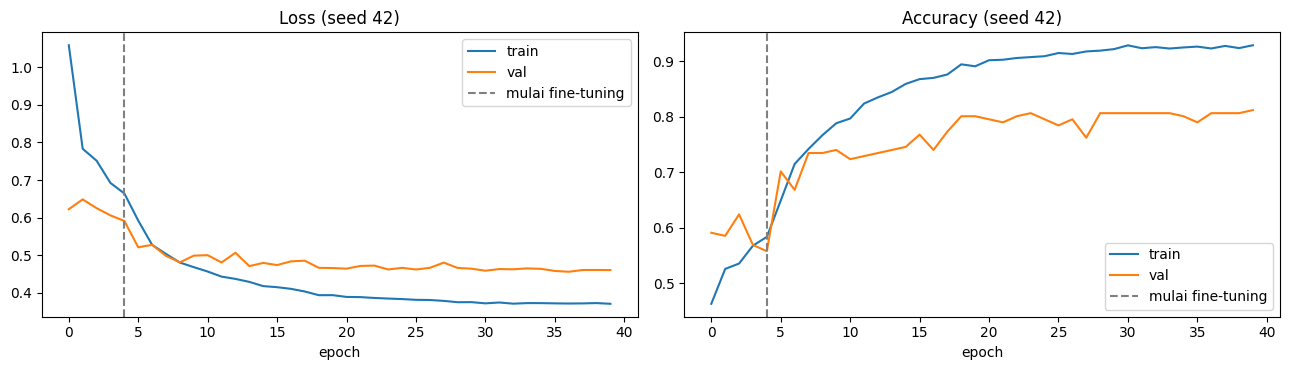

In [16]:
models, histories = [], []
for s in SEEDS:
    m, H, split_at = train_one(s, tr_paths, tr_labels, va_paths, va_labels)
    models.append(m); histories.append((s, H, split_at))

fig, ax = plt.subplots(len(histories), 2, figsize=(13, 3.8 * len(histories)), squeeze=False)
for r, (s, H, split_at) in enumerate(histories):
    for c, (met, title) in enumerate([("loss", "Loss"), ("accuracy", "Accuracy")]):
        ax[r][c].plot(H[met], label="train"); ax[r][c].plot(H["val_" + met], label="val")
        ax[r][c].axvline(split_at - 1, color="gray", ls="--", label="mulai fine-tuning")
        ax[r][c].set_title(f"{title} (seed {s})"); ax[r][c].set_xlabel("epoch"); ax[r][c].legend()
plt.tight_layout(); plt.show()

## 11. Evaluasi pada data test

**Langkah:** menghitung prediksi pada data test dan melaporkan metrik.

**Metode:**
- **Ensemble:** probabilitas model dari beberapa seed dirata-ratakan (bila ada lebih dari satu model).
- **TTA:** probabilitas gambar asli dan versi flip horizontal dirata-ratakan (opsional).
- **Accuracy dan macro-F1:** macro-F1 memberi bobot sama pada setiap kelas sehingga kelas kecil tetap dihitung.
- **Bootstrap 95% CI:** data test diambil ulang dengan pengembalian (1000 kali) untuk menaksir ketidakpastian akibat ukuran sampel.
- **Precision/recall/F1 per kelas dan confusion matrix.**
- **Metrik ordinal:** MAE tingkat dan akurasi ±1 level, karena tingkat keparahan berurutan.
- **Metrik kelompok:** akurasi dan macro-F1 pada kelompok kelas yang lebih kasar (`COARSE_GROUPS`).

,Varian,Accuracy,Macro-F1
0,Model #1,0.7536,0.7709
1,Model #1 + TTA,0.7536,0.7709


Pipeline akhir: ensemble=False, TTA=False
Accuracy : 0.7536  (95% CI 0.652 - 0.855)
Macro-F1 : 0.7709  (95% CI 0.670 - 0.863)  n=69

              precision    recall  f1-score   support

        IGA0      1.000     0.889     0.941         9
        IGA1      0.824     0.875     0.848        16
        IGA2      0.650     0.684     0.667        19
        IGA3      0.667     0.571     0.615        14
        IGA4      0.750     0.818     0.783        11

    accuracy                          0.754        69
   macro avg      0.778     0.768     0.771        69
weighted avg      0.755     0.754     0.753        69



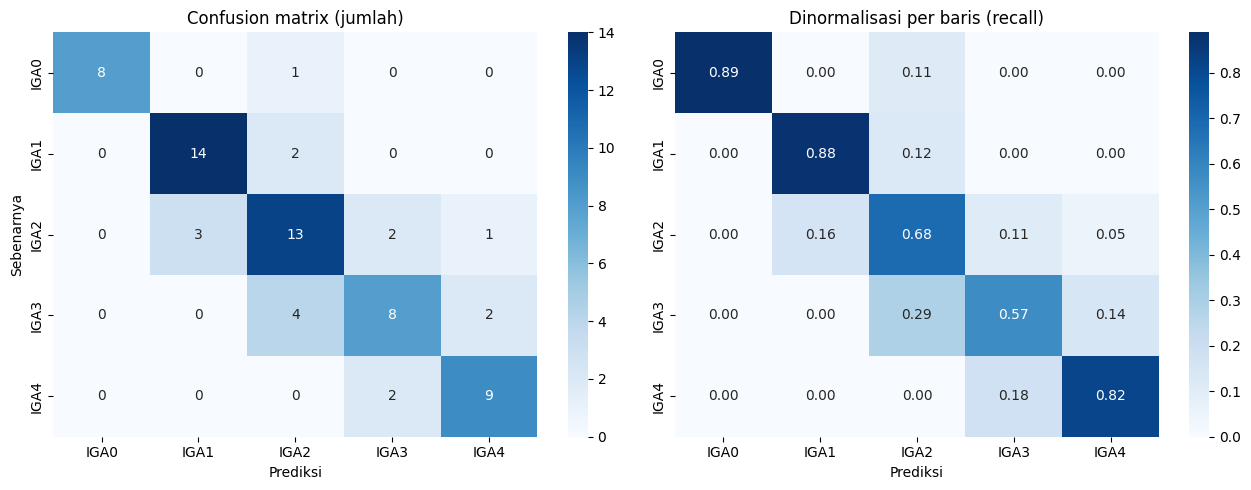

MAE tingkat      : 0.275
Akurasi +-1 level: 0.9710


In [17]:
def get_probs(model, ds, tta):
    out = []
    for xb, _ in ds:
        p = model(xb, training=False).numpy()
        if tta:
            p = (p + model(tf.reverse(xb, axis=[2]), training=False).numpy()) / 2.0
        out.append(p)
    return np.concatenate(out)

eval_ds = make_ds(te_paths, te_labels)
y_eval = np.array(te_labels)
P_eval = {t: [get_probs(m, eval_ds, t) for m in models] for t in (False, True)}

def combine(P, tta, ens):
    return np.mean(P[tta] if ens else P[tta][:1], axis=0)

def score(probs, y):
    pred = probs.argmax(1)
    return accuracy_score(y, pred), f1_score(y, pred, average="macro")

rows = [("Model #1", *score(combine(P_eval, False, False), y_eval)),
        ("Model #1 + TTA", *score(combine(P_eval, True, False), y_eval))]
if len(models) > 1:
    rows += [(f"Ensemble {len(models)} model", *score(combine(P_eval, False, True), y_eval)),
             (f"Ensemble {len(models)} model + TTA", *score(combine(P_eval, True, True), y_eval))]
display(pd.DataFrame(rows, columns=["Varian", "Accuracy", "Macro-F1"]).round(4))

ens_final = USE_ENSEMBLE and len(models) > 1
probs_final = combine(P_eval, USE_TTA, ens_final)
y_pred = probs_final.argmax(1)
print(f"Pipeline akhir: ensemble={ens_final}, TTA={USE_TTA}")

def bootstrap_ci(y, pred, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    a, f = [], []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        a.append(accuracy_score(y[i], pred[i])); f.append(f1_score(y[i], pred[i], average="macro"))
    return np.percentile(a, [2.5, 97.5]), np.percentile(f, [2.5, 97.5])

acc, f1m = score(probs_final, y_eval)
ci_a, ci_f = bootstrap_ci(y_eval, y_pred)
print(f"Accuracy : {acc:.4f}  (95% CI {ci_a[0]:.3f} - {ci_a[1]:.3f})")
print(f"Macro-F1 : {f1m:.4f}  (95% CI {ci_f[0]:.3f} - {ci_f[1]:.3f})  n={len(y_eval)}\n")
print(classification_report(y_eval, y_pred, target_names=class_names, digits=3, zero_division=0))

cm = confusion_matrix(y_eval, y_pred, labels=range(NUM_CLASSES))
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax[0])
ax[0].set_title("Confusion matrix (jumlah)"); ax[0].set_xlabel("Prediksi"); ax[0].set_ylabel("Sebenarnya")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax[1])
ax[1].set_title("Dinormalisasi per baris (recall)"); ax[1].set_xlabel("Prediksi")
plt.tight_layout(); plt.show()

if ORDINAL_ORDER is not None:
    rank_map = {n: i for i, n in enumerate([c for c in ORDINAL_ORDER if c in class_names])}
    r_t = np.array([rank_map[class_names[i]] for i in y_eval])
    r_p = np.array([rank_map[class_names[i]] for i in y_pred])
    print(f"MAE tingkat      : {np.abs(r_t - r_p).mean():.3f}")
    print(f"Akurasi +-1 level: {(np.abs(r_t - r_p) <= 1).mean():.4f}")

if COARSE_GROUPS:
    assert all(c in COARSE_GROUPS for c in class_names), "COARSE_GROUPS belum memuat semua kelas."
    gnames = sorted(set(COARSE_GROUPS[c] for c in class_names), key=lambda g: [COARSE_GROUPS[c] for c in class_names].index(g))
    gmap = np.array([gnames.index(COARSE_GROUPS[c]) for c in class_names])
    gt, gp = gmap[y_eval], gmap[y_pred]
    print(f"\nEvaluasi kelompok {gnames}: accuracy={accuracy_score(gt, gp):.4f}, macro-F1={f1_score(gt, gp, average='macro'):.4f}")
    print(classification_report(gt, gp, target_names=gnames, digits=3, zero_division=0))

## 12. Uji ketahanan terhadap latar

**Langkah:** membandingkan performa pada data test asli dengan data test yang piksel latar hitamnya diganti abu-abu netral.
**Metode:** perturbasi terkontrol pada latar. Penurunan performa yang besar menunjukkan prediksi bergantung pada latar, bukan hanya pada kulit/lesi.

In [18]:
def eval_variant(ds):
    p = np.mean([get_probs(m, ds, False) for m in models], axis=0)
    return score(p, y_eval)

frac_black = np.array([black_frac(p) for p in te_paths])
print(f"Gambar test dengan >5% piksel hitam: {(frac_black > 0.05).mean():.0%}")
res = [("Asli", *eval_variant(eval_ds)),
       ("Latar hitam -> abu-abu", *eval_variant(make_ds(te_paths, te_labels, bg_fill=127)))]
display(pd.DataFrame(res, columns=["Data test", "Accuracy", "Macro-F1"]).round(4))

Gambar test dengan >5% piksel hitam: 71%


,Data test,Accuracy,Macro-F1
0,Asli,0.7536,0.7709
1,Latar hitam -> abu-abu,0.7681,0.7955


## 13. Analisis kesalahan

**Langkah:** menampilkan kesalahan prediksi dengan keyakinan model tertinggi.
**Metode:** pengurutan kesalahan berdasarkan probabilitas kelas terprediksi. Pola yang muncul (label meragukan, gambar buram, watermark, latar) dipakai untuk mengaudit kualitas data.

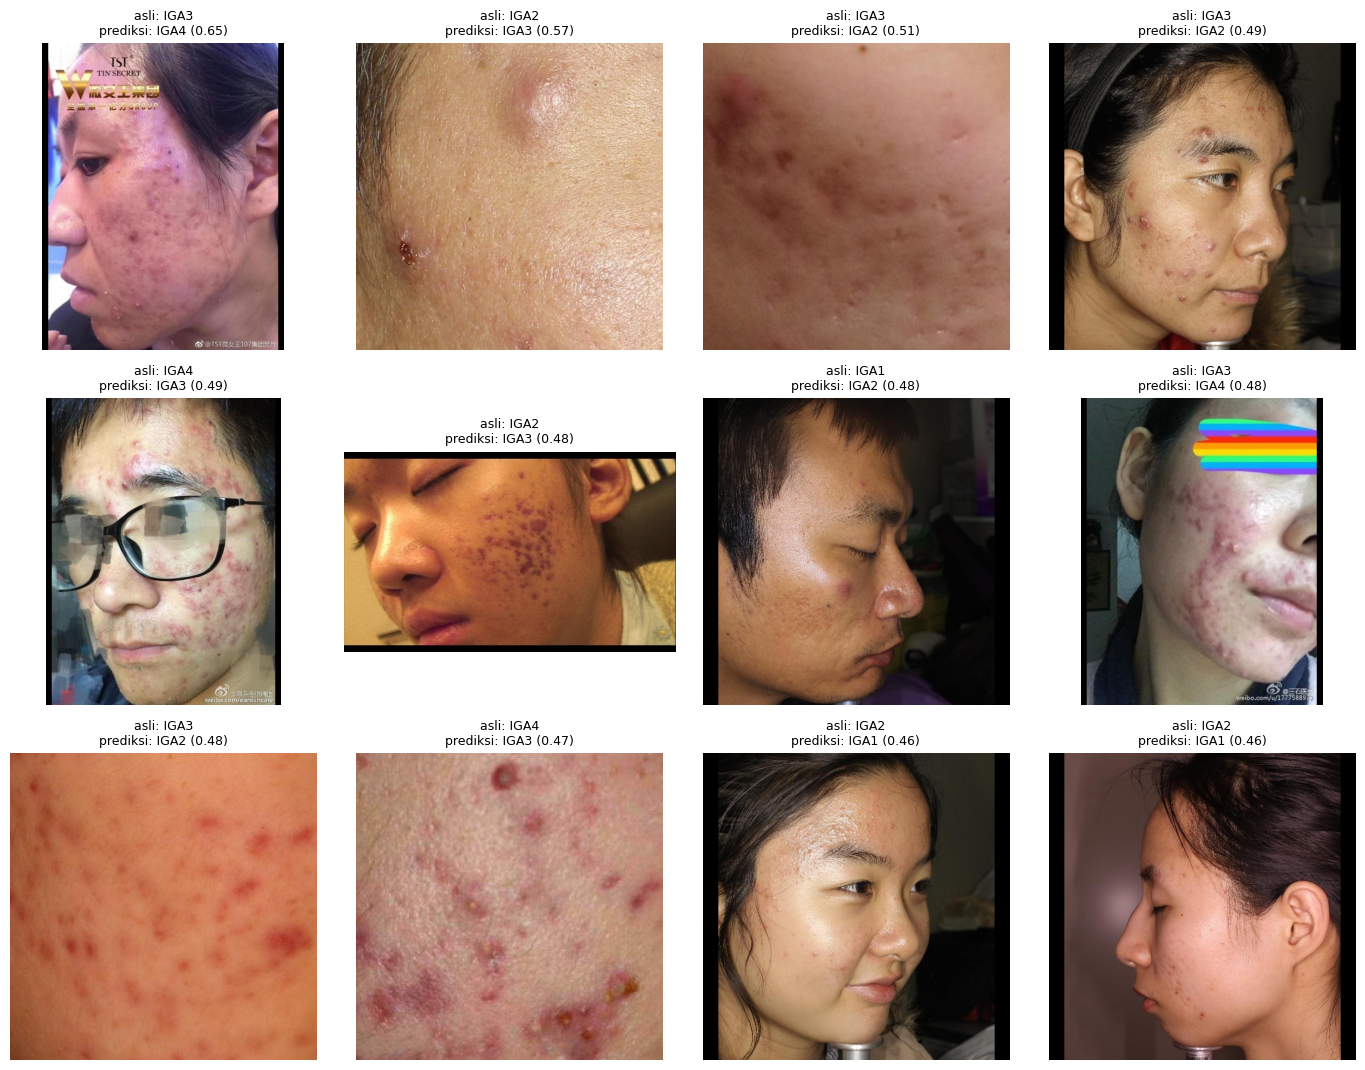

In [19]:
conf = probs_final.max(1)
wrong = np.where(y_pred != y_eval)[0]
top = wrong[np.argsort(-conf[wrong])][:12]
if len(top) == 0:
    print("Tidak ada kesalahan pada data evaluasi.")
else:
    cols = 4
    nr = int(np.ceil(len(top) / cols))
    fig, axes = plt.subplots(nr, cols, figsize=(14, 3.6 * nr), squeeze=False)
    for a in axes.ravel():
        a.axis("off")
    for a, i in zip(axes.ravel(), top):
        a.imshow(keras.utils.load_img(te_paths[i]))
        a.set_title(f"asli: {class_names[y_eval[i]]}\nprediksi: {class_names[y_pred[i]]} ({conf[i]:.2f})", fontsize=9)
    plt.tight_layout(); plt.show()

## 14. Grad-CAM

**Langkah:** memvisualisasikan area gambar yang paling memengaruhi prediksi (contoh benar dan salah).
**Metode:** Grad-CAM. Gradien skor kelas terhadap feature map konvolusi terakhir dirata-ratakan per channel menjadi bobot; feature map berbobot dijumlahkan, di-ReLU, dinormalisasi, lalu di-resize dan ditumpuk pada gambar. Area panas yang berada di latar atau tepi gambar mengindikasikan prediksi tidak berbasis lesi.

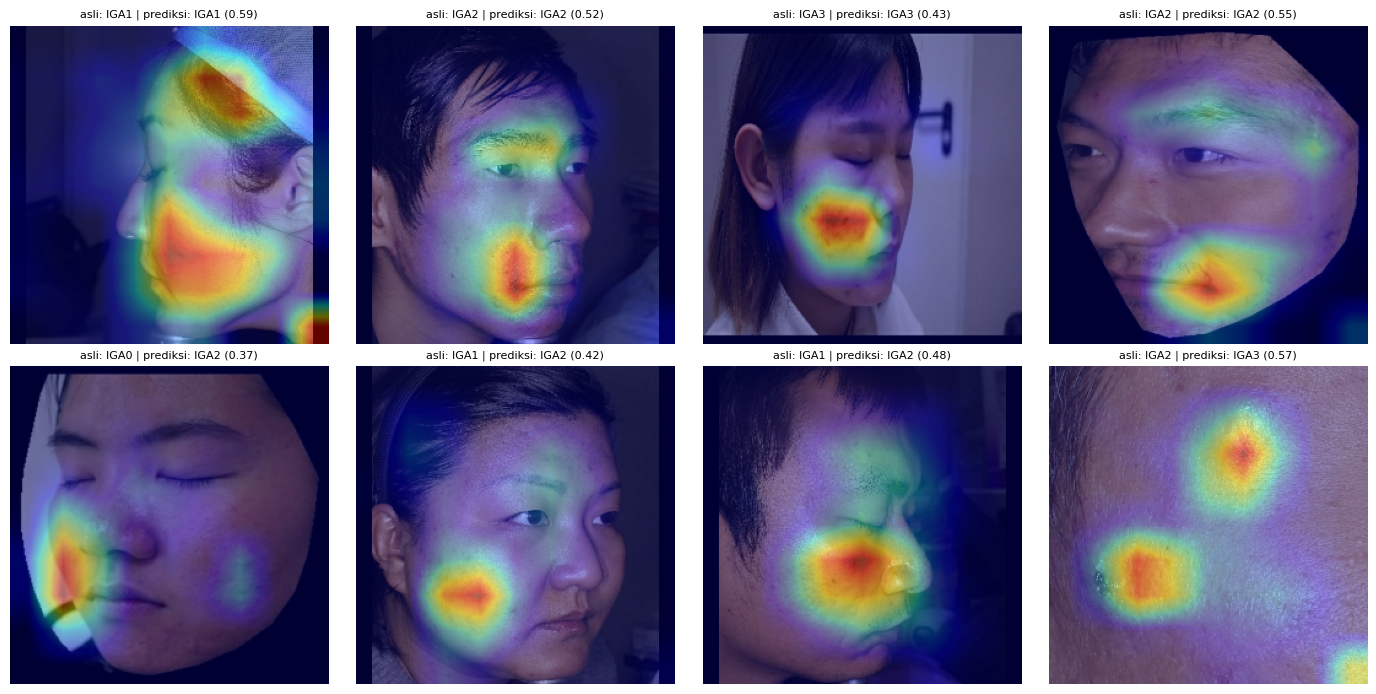

In [20]:
m0 = models[0]
base_m = next(l for l in m0.layers if isinstance(l, keras.Model) and "efficientnet" in l.name.lower())
last_conv_model = keras.Model(base_m.input, base_m.get_layer("top_activation").output)
clf_in = keras.Input(shape=last_conv_model.output.shape[1:])
h = clf_in
for l in m0.layers[m0.layers.index(base_m) + 1:]:
    h = l(h)
classifier_model = keras.Model(clf_in, h)

def grad_cam(img_array):
    x = tf.convert_to_tensor(img_array[None, ...], dtype=tf.float32)
    with tf.GradientTape() as tape:
        conv_out = last_conv_model(x, training=False)
        tape.watch(conv_out)
        preds = classifier_model(conv_out, training=False)
        cls = int(tf.argmax(preds[0]))
        score_c = preds[:, cls]
    grads = tape.gradient(score_c, conv_out)
    w = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv_out * w[:, None, None, :], axis=-1)[0])
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], (IMG_SIZE, IMG_SIZE)).numpy()[..., 0]
    return cam, cls, preds.numpy()[0]

right = np.where(y_pred == y_eval)[0]
pick = list(np.random.default_rng(0).choice(right, min(4, len(right)), replace=False)) + list(wrong[:4])
if pick:
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for a in axes.ravel():
        a.axis("off")
    for a, i in zip(axes.ravel(), pick):
        img = decode(te_paths[i]).numpy()
        cam, cls, probs = grad_cam(img)
        a.imshow(img.astype("uint8")); a.imshow(cam, cmap="jet", alpha=0.4)
        a.set_title(f"asli: {class_names[y_eval[i]]} | prediksi: {class_names[cls]} ({probs[cls]:.2f})", fontsize=8)
    plt.tight_layout(); plt.show()

## 15. Ekspor model

**Langkah:** menyimpan model dan mengonversinya ke TFLite untuk aplikasi mobile.

In [23]:
@tf.function(input_signature=[tf.TensorSpec([1, IMG_SIZE, IMG_SIZE, 3], tf.float32, name="image")])
def serve(x):
    return export_model(x, training=False)

converter = tf.lite.TFLiteConverter.from_concrete_functions([serve.get_concrete_function()], export_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_types = [tf.float16]
try:
    tflite_bytes = converter.convert()
except Exception as e:
    errs = [l for l in str(e).splitlines() if any(k in l.lower() for k in ("error", "legalize", "failed"))]
    print("Konversi TFLite gagal. Baris error:", *errs[:10], sep="\n")
    raise

## 16. Cross-validation (opsional)

**Langkah:** mengevaluasi pipeline pada beberapa pembagian data berbeda untuk memperoleh estimasi performa yang lebih stabil daripada satu split kecil.

**Metode:** *Stratified Group K-Fold*. Seluruh gambar (train+valid+test) digabung; kelas dijaga proporsinya per fold dan gambar dari grup yang sama (gambar asli dan salinan augmentasinya) selalu berada di fold yang sama sehingga tidak terjadi kebocoran. Validasi (untuk early stopping) diambil dari sisa data secara group-wise. Ringkasan dilaporkan sebagai rata-rata ± simpangan baku antar fold.

Catatan: gambar yang dievaluasi pada fold ini mencakup salinan hasil augmentasi Roboflow, sehingga angkanya tidak identik dengan evaluasi pada test resmi (bagian 11). Setiap fold melatih satu model penuh; `FOLDS_TO_RUN` menentukan fold yang dijalankan.

In [24]:
if RUN_CV:
    P, Y = POOL_PATHS, POOL_LABELS
    G = np.array([group_of(p) for p in P])
    sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    cv_rows = []
    for k, (trv, te) in enumerate(sgkf.split(P, Y, G)):
        if k not in FOLDS_TO_RUN:
            continue
        inner = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
        tr_i, va_i = next(inner.split(P[trv], Y[trv], G[trv]))
        tr_idx, va_idx = trv[tr_i], trv[va_i]
        keras.backend.clear_session()
        mk, _, _ = train_one(SEEDS[0], P[tr_idx], Y[tr_idx], P[va_idx], Y[va_idx], tag=f"cv{k}")
        pk = get_probs(mk, make_ds(P[te], Y[te]), USE_TTA)
        a, f = score(pk, Y[te])
        cv_rows.append({"fold": k, "n_test": len(te), "accuracy": a, "macro_F1": f})
        print(cv_rows[-1])
    df_cv = pd.DataFrame(cv_rows)
    display(df_cv.round(4))
    print(f"Rata-rata  accuracy={df_cv.accuracy.mean():.4f} +- {df_cv.accuracy.std(ddof=0):.4f} | "
          f"macro-F1={df_cv.macro_F1.mean():.4f} +- {df_cv.macro_F1.std(ddof=0):.4f}")
else:
    print("RUN_CV=False: bagian ini dilewati.")

RUN_CV=False: bagian ini dilewati.


## 17. Export Model Untuk Server



In [25]:
import json

with open("outputs/acne_severity_fp16.tflite", "wb") as f:
    f.write(tflite_bytes)
with open("outputs/labels.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(class_names))
with open("outputs/meta.json", "w") as f:
    json.dump({"backbone": BACKBONE, "img_size": IMG_SIZE, "classes": class_names,
               "input_range": "0-255 float32 RGB", "content_crop": USE_CONTENT_CROP,
               "ensemble_members": len(models) if ens_final else 1, "tta_flip": USE_TTA}, f, indent=2)
models[0].save("outputs/acne_model_seed42.keras")   # untuk server FastAPI

print(f"TFLite: {len(tflite_bytes) / 1e6:.1f} MB")

# Verifikasi TFLite vs model Keras pada satu gambar
interp = tf.lite.Interpreter(model_content=tflite_bytes)
interp.allocate_tensors()
inp_d, out_d = interp.get_input_details()[0], interp.get_output_details()[0]
x1 = xb.numpy()[:1].astype("float32")
interp.set_tensor(inp_d["index"], x1); interp.invoke()
print("Selisih maks TFLite vs Keras:",
      float(np.abs(interp.get_tensor(out_d["index"])[0] - export_model(x1).numpy()[0]).max()))

TFLite: 15.6 MB


    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    


Selisih maks TFLite vs Keras: 0.07421618700027466
